In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv')
print(df.isnull().sum()[lambda s: s > 0])

categorical = [c for c in df.columns if df[c].dtype == object]
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

lead_source          128
industry             134
annual_income        181
employment_status    100
location              63
dtype: int64


In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [10]:
for c in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(df_train.converted, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(df_train.converted, -df_train[c])
    print(c, round(auc, 4))

lead_score 0.6145
number_of_courses_viewed 0.7636
interaction_count 0.7383
annual_income 0.552


In [12]:
def train(d, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(d[categorical + numerical].to_dict('records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, d.converted)
    return dv, model

def predict(d, dv, model):
    X = dv.transform(d[categorical + numerical].to_dict('records'))
    return model.predict_proba(X)[:, 1]

In [13]:
dv, model = train(df_train)
y_pred = predict(df_val, dv, model)
y_val = df_val.converted.values
print(round(roc_auc_score(y_val, y_pred), 3))

0.817


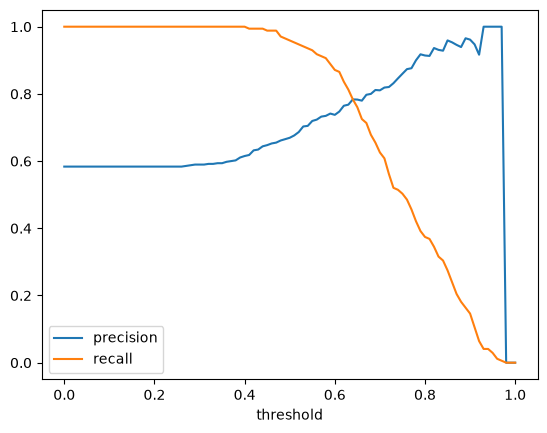

Q3: 0.64
Q4: 0.57


In [14]:
rows = []
for t in np.arange(0, 1.01, 0.01):
    pred = y_pred >= t
    tp = (pred & (y_val == 1)).sum()
    fp = (pred & (y_val == 0)).sum()
    fn = (~pred & (y_val == 1)).sum()
    p = tp / (tp + fp) if tp + fp > 0 else 0
    r = tp / (tp + fn)
    f1 = 2 * p * r / (p + r) if p + r > 0 else 0
    rows.append((round(t, 2), p, r, f1))

scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.show()

nz = scores[(scores.precision > 0) | (scores.recall > 0)]
print('Q3:', nz.loc[(nz.precision - nz.recall).abs().idxmin(), 'threshold'])
print('Q4:', scores.loc[scores.f1.idxmax(), 'threshold'])

In [15]:
def cv_scores(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]
        dv, model = train(d_tr, C)
        aucs.append(roc_auc_score(d_va.converted, predict(d_va, dv, model)))
    return np.mean(aucs), np.std(aucs)

print('std:', round(cv_scores(1.0)[1], 3))

std: 0.036


In [16]:
for C in [0.000001, 0.001, 1]:
    mean, std = cv_scores(C)
    print(C, round(mean, 3), round(std, 3))

1e-06 0.56 0.024
0.001 0.867 0.029
1 0.822 0.036
